# Detecção de amastigotas fora do macrófago — experimento 2 (melhorias)

- Autor: Clésio Gonçalves
- Esse notebook repete o experimento de `deteccao_yolov11nano.ipynb` (mesmos recortes 512x512 e mesma divisão de 6 folds por lâmina), mas incorpora melhorias voltadas a aumentar a detecção de objetos muito pequenos (leishmania fora do macrófago), que foi o principal limitador de desempenho no experimento anterior (mAP50 médio 0.439 ± 0.123).

## Melhorias adotadas

1. **Cabeça de detecção P2/stride-4 extra** — arquitetura YOLO11n customizada (`yolo11-p2.yaml`) com um quarto nível de detecção em resolução mais fina (P2), além dos níveis padrão P3/P4/P5. Essa é a mudança estrutural com maior potencial de ganho para objetos pequenos, mantendo a família *nano* (poucos parâmetros). O backbone é inicializado com os pesos pré-treinados `yolo11n.pt` (transferência parcial).
2. **`imgsz=640`** em vez de 512 — os recortes continuam sendo os mesmos (512x512, não foram regerados), mas o YOLO faz upscale para 640 internamente, dando mais pixels para os objetos pequenos durante o treino/inferência.
3. **Treinamento mais longo e estável**: `epochs=150`, `patience=40` (era 100/30) e `cos_lr=True` para uma queda de *learning rate* mais suave.
4. **Augmentation menos agressivo em escala** (`scale=0.3` em vez do padrão 0.5) para reduzir o encolhimento excessivo de objetos já minúsculos durante o treino.
5. **`single_cls=True`** explícito, já que o problema é de classe única.
6. **Novo diagnóstico visual**: comparação lado a lado das caixas marcadas pelo especialista (anotação original) com as caixas detectadas pela YOLO, sobre a mesma imagem.

As 6 lâminas/folds e o pré-processamento (remapeamento para classe única `leishmania`) são idênticos ao experimento anterior, para permitir comparação direta dos resultados.

## Utilização da GPU

In [1]:
!nvidia-smi

Tue Jun 23 02:02:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0 Off |                  N/A |
|  0%   34C    P8             16W /  300W |      15MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''

In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V

Author: Clésio Gonçalves

PIL        : 12.0.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

## Parâmetros do experimento

In [7]:
# Diretório com os recortes (512x512) de macrófagos infectados, organizados por lâmina — gerados em pre_processamento_dataset_recortes.ipynb
diretorio_recortes = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")
extensao = '.png'

# Tamanho de treino/inferência da rede (upscale dos recortes 512x512 -> mais pixels para objetos pequenos)
tamanho_imagem = 640

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Diretórios de trabalho (dataset YOLO compartilhado com o experimento anterior; runs em pasta própria)
diretorio_yolo_folds = os.path.join(diretorio_raiz, "yolo_folds_leishmania")
diretorio_runs = os.path.join(diretorio_raiz, "runs_leishmania_kfold_p2")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Arquitetura customizada YOLO11n + cabeça extra P2 (stride 4), escrita pela célula "Arquitetura" abaixo
caminho_arquitetura_p2 = os.path.join(os.getcwd(), "yolo11-p2.yaml")
caminho_pesos_pretreinados = 'yolo11n.pt'

# Hiperparâmetros de treinamento (segunda rodada, focada em objetos pequenos)
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=16,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    scale=0.3,
    single_cls=True,
    verbose=False,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica ao experimento anterior, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')

,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

Mesma lógica do experimento anterior: imagens só são referenciadas (link simbólico), `.txt` reescritos com apenas a classe `leishmania` remapeada para o índice `0`, e as lâminas de teste organizadas também em subpastas individuais (diagnóstico por lâmina).

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")

Fold 1: treino=1064 | validação=126 | teste=378


Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449


Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376


Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")

6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Arquitetura customizada: YOLO11n + cabeça extra P2 (stride 4)

O YOLO11 padrão detecta em P3/P4/P5 (stride 8/16/32). Os alvos aqui (leishmania fora do macrófago) têm poucos pixels, próximos do limite de detecção em stride 8. Adicionar uma cabeça P2 (stride 4) — seguindo o mesmo padrão usado em `yolov8-p2.yaml` — dá ao modelo um nível de detecção em resolução duas vezes mais fina, mantendo o backbone *nano* (poucos parâmetros).

In [11]:
conteudo_arquitetura_p2 = """\
# Custom YOLO11 com cabeça extra P2/4 (objetos muito pequenos), baseado em yolo11.yaml + padrão yolov8-p2.yaml
nc: 80
scales:
  n: [0.50, 0.25, 1024]
  s: [0.50, 0.50, 1024]
  m: [0.50, 1.00, 512]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.50, 512]

backbone:
  - [-1, 1, Conv, [64, 3, 2]] # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]] # 1-P2/4
  - [-1, 2, C3k2, [256, False, 0.25]]
  - [-1, 1, Conv, [256, 3, 2]] # 3-P3/8
  - [-1, 2, C3k2, [512, False, 0.25]]
  - [-1, 1, Conv, [512, 3, 2]] # 5-P4/16
  - [-1, 2, C3k2, [512, True]]
  - [-1, 1, Conv, [1024, 3, 2]] # 7-P5/32
  - [-1, 2, C3k2, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]] # 9
  - [-1, 2, C2PSA, [1024]] # 10

head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]] # cat backbone P4
  - [-1, 2, C3k2, [512, False]] # 13

  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]] # cat backbone P3
  - [-1, 2, C3k2, [256, False]] # 16

  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]] # cat backbone P2
  - [-1, 2, C3k2, [128, False]] # 19 (P2/4-xsmall)

  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]] # cat head P3
  - [-1, 2, C3k2, [256, False]] # 22 (P3/8-small)

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]] # cat head P4
  - [-1, 2, C3k2, [512, False]] # 25 (P4/16-medium)

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]] # cat head P5
  - [-1, 2, C3k2, [1024, True]] # 28 (P5/32-large)

  - [[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)
"""

with open(caminho_arquitetura_p2, 'w') as f:
    f.write(conteudo_arquitetura_p2)

print(f"Arquitetura escrita em '{caminho_arquitetura_p2}'.")

Arquitetura escrita em '/mnt/arquivos/Doutorado/deteccao_leish_fora_macrofago/yolo11-p2.yaml'.


## Treinamento dos 6 folds (YOLO11n + P2)

Treinamento local na GPU. Pesos pré-treinados (`yolo11n.pt`) são transferidos para as camadas compatíveis do backbone antes do treino. Caso o `best.pt` de um fold já exista, o treinamento desse fold é pulado (idempotente).

In [12]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    if os.path.isfile(caminho_best):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_arquitetura_p2)
        modelo.load(caminho_pesos_pretreinados)  # transferência dos pesos pré-treinados compatíveis do backbone
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best

WARNING ⚠️ no model scale passed. Assuming scale='n'.


Transferred 297/593 items from pretrained weights


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/mnt/arquivos/Doutorado/deteccao_leish_fora_macrofago/yolo11-p2.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1


... (16,561 outputs left out)

                   all         96        831      0.565      0.413      0.436      0.205


Speed: 0.1ms preprocess, 0.9ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/runs_leishmania_kfold_p2/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/runs_leishmania_kfold_p2/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [13]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11-p2 summary (fused): 121 layers, 2,658,868 parameters, 0 gradients, 10.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5892.9±1714.5 MB/s, size: 258.3 KB)



val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 6.9Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 2.2it/s 0.1s<10.3s

... (90 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 25.3it/s 1.2s

                   all        480       1634      0.329      0.389      0.277      0.116


Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.528812,0.534530,0.485920,0.161790
2,"leish_2, leish_7",0.577283,0.584274,0.573804,0.230085
3,"leish_1, leish_8",0.398843,0.426221,0.328338,0.128257
4,"leish_4, leish_9",0.421375,0.549378,0.410596,0.173081
5,"leish_1, leish_7",0.547584,0.470135,0.460631,0.175320
6,"leish_2, leish_8",0.329368,0.388617,0.276513,0.115569


In [14]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)

,média,desvio_padrão
precisao,0.4672,0.0981
recall,0.4922,0.0763
mAP50,0.4226,0.1083
mAP50-95,0.1640,0.0405


## Comparação com o experimento anterior (`yolo11n`, `imgsz=512`, sem cabeça P2)

Valores do experimento anterior (`deteccao_yolov11nano.ipynb`), copiados aqui apenas para referência visual — mesmos 6 folds.

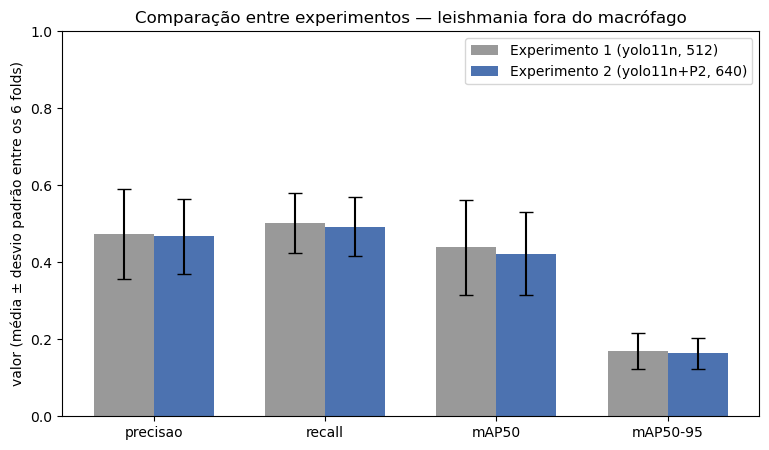

In [15]:
%matplotlib inline
# Médias e desvios padrão do experimento anterior (deteccao_yolov11nano.ipynb), para comparação
resumo_baseline = pd.DataFrame({
    'média': [0.4735, 0.5012, 0.4391, 0.1695],
    'desvio_padrão': [0.1164, 0.0780, 0.1229, 0.0457],
}, index=['precisao', 'recall', 'mAP50', 'mAP50-95'])

metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']
x = np.arange(len(metricas_plot))
largura = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - largura / 2, resumo_baseline.loc[metricas_plot, 'média'], largura,
       yerr=resumo_baseline.loc[metricas_plot, 'desvio_padrão'], capsize=5, label='Experimento 1 (yolo11n, 512)', color='#999999')
ax.bar(x + largura / 2, resumo_metricas.loc[metricas_plot, 'média'], largura,
       yerr=resumo_metricas.loc[metricas_plot, 'desvio_padrão'], capsize=5, label='Experimento 2 (yolo11n+P2, 640)', color='#4C72B0')

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('valor (média ± desvio padrão entre os 6 folds)')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend()
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [16]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11-p2 summary (fused): 121 layers, 2,658,868 parameters, 0 gradients, 10.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4870.8±771.5 MB/s, size: 269.7 KB)



val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 5.3Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test_lamina/leish_3.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 2.3it/s 0.1s<0.4s

... (139 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 25.5it/s 0.9s

                   all        353        992      0.354      0.414      0.309      0.134


Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.578845,0.451526,0.450002,0.185431
1,leish_1,5,0.437669,0.231047,0.252231,0.101329
2,leish_2,2,0.369226,0.422118,0.310323,0.124942
3,leish_2,6,0.318549,0.355140,0.254398,0.094884
4,leish_3,1,0.223473,0.600000,0.321956,0.124409
5,leish_4,4,0.286744,0.257576,0.189102,0.085084
6,leish_5,1,0.531825,0.536296,0.488699,0.162732
7,leish_7,2,0.628685,0.638541,0.638208,0.256623
8,leish_7,5,0.580293,0.580784,0.571848,0.216706
9,leish_8,3,0.360837,0.461540,0.322751,0.123126


In [17]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)

precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.5083  0.0998     2  0.3413  0.1559     2  0.3511  0.1398     2   
leish_2   0.3439  0.0358     2  0.3886  0.0474     2  0.2824  0.0395     2   
leish_3   0.2235     NaN     1  0.6000     NaN     1  0.3220     NaN     1   
leish_4   0.2867     NaN     1  0.2576     NaN     1  0.1891     NaN     1   
leish_5   0.5318     NaN     1  0.5363     NaN     1  0.4887     NaN     1   
leish_7   0.6045  0.0342     2  0.6097  0.0408     2  0.6050  0.0469     2   
leish_8   0.3575  0.0047     2  0.4379  0.0334     2  0.3157  0.0100     2   
leish_9   0.4711     NaN     1  0.5918     NaN     1  0.4675     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.1434  0.0595     2  
leish_2   0.1099  0.0213     2  
leish_3   0.1244     NaN     1  
leish_4   0.0851     NaN     1  
leish_5   0.1627     NaN     1  
leish_7   0.2367  0.0282     2  
leish_8   0.1288  0.0080     2  
leish_9   0.1975     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima.

In [18]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img = Image.open(caminho_imagem)
    largura, altura = img.size
    eixo.imshow(img)

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']

Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


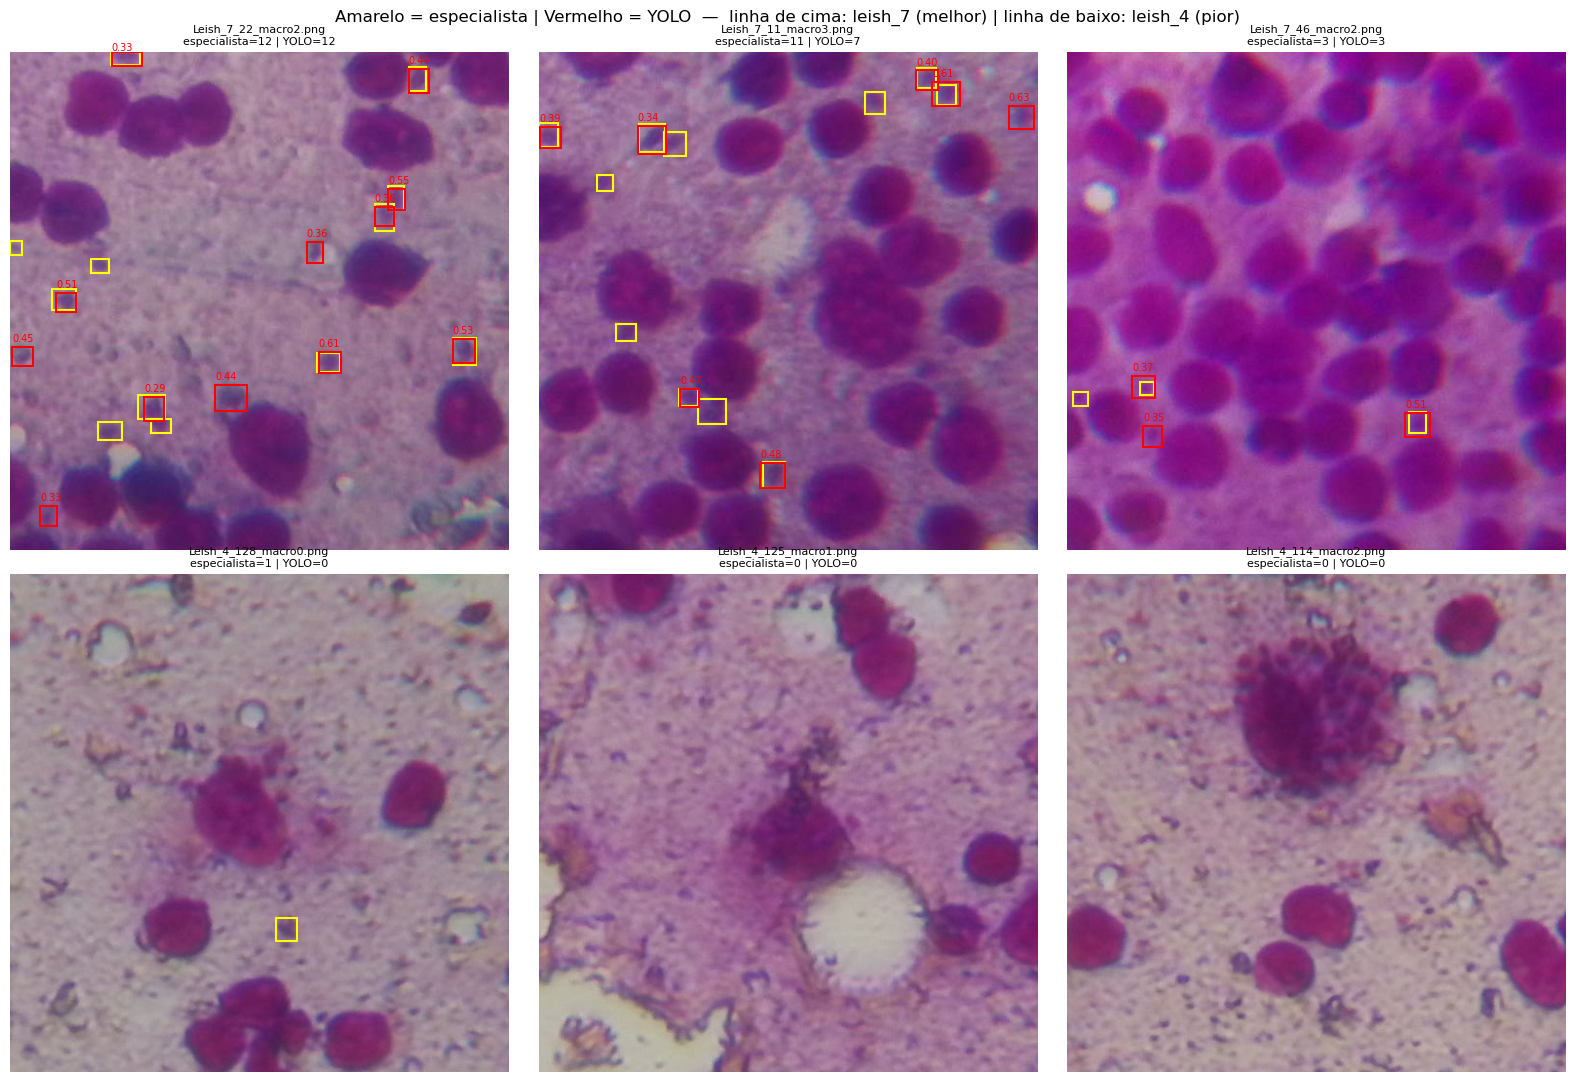

In [19]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()